# Two-dimensional antiferromagnet: the bound from equilibrium data alone

This notebook covers Sec. VI of the paper and produces Fig. 5 (`heisenberg_bound`).

The other two notebooks treat models whose dynamics can be computed. This one is the opposite
case, and it is the point of the section: a strongly correlated two-dimensional lattice whose
real-time dynamics is out of reach, but whose *thermal* state is accessible to sign-free
quantum Monte Carlo. Everything the bound needs is a static susceptibility and an equilibrium
variance, so the bound can be evaluated where the thing it bounds cannot.

What is claimed is correspondingly narrow, and worth stating before the figures:

* the bound is a **necessary** condition — nothing here shows that the lattice thermalizes;
* no claim is made that the bound is tight;
* the intractability of the dynamics is argued, not proved.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

import planckian as pk
import plotstyle as ps
import schematic as sc
from planckian import read_csv, select, column, sort_by
from plotstyle import L_COLOR, L_MARK, EPS_COLOR_QMC, RED, BLUES, grid

DATA = Path('data/heisenberg')
FIGS = Path('figures'); FIGS.mkdir(exist_ok=True)
ps.setup()

BLUES_DARK = BLUES[3]
EPSMAX = pk.EPS_MAX

## 1. Model

A spin-1/2 Heisenberg antiferromagnet on an $L\times L$ square lattice with periodic boundaries,
$J>0$, in units $J=1$. The system $S$ is **one spin**, site 0; the bath $B$ is the rest of the
lattice; the interaction is the four bonds of that site [Eq. (45)]:

$$H_{\rm tot}=\underbrace{\tfrac{x}{2}\,\sigma^z_0}_{H_S(x)}
  \;+\;\underbrace{J\,\mathbf S_0\cdot\!\!\sum_{j\in\partial 0}\!\mathbf S_j}_{V}
  \;+\;\underbrace{J\!\!\sum_{\langle ij\rangle\not\ni 0}\!\!\mathbf S_i\cdot\mathbf S_j}_{H_B},$$

with $\partial0$ the four neighbours of site 0 [Eq. (41)]. There is no separate coupling
constant. In a homogeneous lattice $V$ and $H_B$ have the same strength, so **increasing $J$ at
fixed temperature is the same as lowering $k_BT/J$**: the horizontal axis of the figure is the
coupling axis, read right to left. The reference system Hamiltonian is $\bar H_S=0$ and the
family direction is a local field, $\hat\kappa=\sigma^z_0/2$, with $\|\hat\kappa\|=1$.

### Two exact symmetry facts

These follow from $H_{\rm tot}$ and are not approximations.

**SU(2).** At $x=0$ spin-rotation symmetry makes the MFG state of one site exactly
$\tilde\omega=\mathbb I/2$ at every $T$, $J$ and $L$, and the static response matrix isotropic.
Equation (25) — case (iii) of Sec. III C, with $\bm b=0$ — then has nothing left to optimize
over, and with $\mathrm{Var}_{\tilde\omega}(\sigma^z_0)=1$ and $\|\hat\kappa\|=1$ it gives
[Eq. (42)]

$$\widetilde\chi=\frac{\xi_{\sigma\sigma}}{2\beta}
  =-\frac{\partial\langle\sigma^z_0\rangle_{\tilde\omega_x}}{\partial(\beta x)}\bigg|_{x=0}
  =\frac{r_\kappa}{2},$$

the optimum over **all** single-spin perturbations, not just over $\sigma^z$. One static
susceptibility is the entire locally exact analysis, and it is the initial slope of the
polarization curve in the inset of Fig. 5(a); a free spin, with
$\langle\sigma^z_0\rangle=-\tanh(\beta x/2)$, attains the ceiling $1/2$.

**U(1) about $z$.** With the field on, $H_{\rm tot}$ still commutes with $\sigma^z_0$-rotations
about $z$, so every $\tilde\omega_x$ is diagonal in $\sigma^z_0$ and the Bures angle between two
targets is the classical one,

$$D=\arccos\bigl(\sqrt{pq}+\sqrt{(1-p)(1-q)}\bigr),$$

with $p,q$ the up-populations of site 0 at the two fields. This is `bures_angle_classical` in
`planckian.py`, and it is why the finite-accuracy bound needs nothing but the measured
polarization curve.

## 2. What the Monte Carlo measures

The simulation is a stochastic series expansion (SSE) with heat-bath directed loops
(`src/heisenberg/sse/sse_t.cpp`), a generic solver for any sign-free, number-conserving bond
Hamiltonian with per-bond couplings. A sublattice rotation makes the antiferromagnet sign-free;
there is no Trotter error and the expansion order is not truncated. The local field is split
equally over the four bonds of site 0.

Let $n$ be the expansion order of a configuration and $C_k$ the number of propagated states in
which site 0 has $n_0=k$. The estimators for site 0 are

$$p_k=\Bigl\langle \frac{C_k}{n}\Bigr\rangle,\qquad
  \xi_{kl}=\beta\Bigl\langle\frac{C_kC_l+\delta_{kl}C_k}{n(n+1)}\Bigr\rangle-\beta\,p_kp_l,
  \qquad \xi_{\sigma\sigma}=4\,\xi_{\uparrow\uparrow},$$

and the imaginary-time correlation
$G(\lambda)=\langle\sigma^z_0(\lambda)\,\sigma^z_0\rangle$ at $x=0$ is sampled without bias by
drawing $m\sim\mathrm{Binomial}(n,\lambda/\beta)$ and a uniform position $p$, then averaging
$A_pA_{(p+m)\bmod n}$, 64 samples per $\lambda$ per sweep on a ten-point grid
$\lambda/\beta\in\{0,\tfrac1{32},\dots,\tfrac12\}$.

Statistics: 20 000 equilibration sweeps, then 40 bins of 10 000 sweeps, with jackknife over
bins. Bin independence is checked by re-binning 40 $\to$ 8 and comparing the errors; absence of
drift by comparing the first and last ten bins. The estimators are validated against exact
diagonalization on $4\times2$ clusters (`src/heisenberg/sse/validate_ed.py`); all pulls are
within $2.5\sigma$ with rms $\approx1$.

`local_comb.csv` holds the per-$(L,T)$ combination of independent runs: `chi` is
$\widetilde\chi$, `r` is $r_\kappa$, `GhalfVar` is $G(\beta/2)/\mathrm{Var}$, and the
`G<lambda>` columns are the full normalized correlation curve.

In [2]:
C = read_csv(DATA / 'local_comb.csv')          # runs combined per (L, T)
runs = read_csv(DATA / 'local.csv')            # one row per independent run
print(f'{len(runs)} runs combined into {len(C)} (L, T) points: '
      f'L in {sorted({int(r["L"]) for r in C})}, '
      f'k_BT/J from {min(r["T"] for r in C)} to {max(r["T"] for r in C)}')

# SU(2) says the x = 0 MFG state of one site is exactly I/2. For spin 1/2 the variance is
# Var = 1 - <sigma^z_0>^2 identically, so the whole content of that statement is <sigma^z_0> = 0,
# which the simulation measures rather than imposes. It is also a sensitive test of equilibration.
mz, mz_err, var = column(runs, 'mz', 'mz_err', 'var')
pull = mz / mz_err
print('\nSU(2) prediction <sigma^z_0> = 0 at x = 0, measured on each of the runs:')
print(f'  rms pull over the {len(runs)} runs : {np.sqrt((pull ** 2).mean()):.2f} sigma')
print(f'  largest pull                  : {np.abs(pull).max():.2f} sigma, at '
      f'L = {int(runs[int(np.argmax(np.abs(pull)))]["L"])}, '
      f'k_BT/J = {runs[int(np.argmax(np.abs(pull)))]["T"]:g} (the longest autocorrelation times)')
print(f'  implied |Var - 1| = mz^2       : at most {np.abs(var - 1).max():.1e}')

35 runs combined into 28 (L, T) points: L in [8, 16, 32, 48], k_BT/J from 0.07 to 3.0

SU(2) prediction <sigma^z_0> = 0 at x = 0, measured on each of the runs:
  rms pull over the 35 runs : 1.28 sigma
  largest pull                  : 3.32 sigma, at L = 48, k_BT/J = 0.07 (the longest autocorrelation times)
  implied |Var - 1| = mz^2       : at most 2.6e-02


### The rigorous floor

By Eq. (19), $r_\kappa$ is the *mean* of the normalized imaginary-time correlation over
$[0,\beta]$,

$$r_\kappa=\frac1\beta\int_0^\beta\! d\lambda\,\frac{G(\lambda)}{G(0)},
  \qquad G(0)=G(\beta)=\mathrm{Var}_{\tilde\omega}(\sigma^z_0).$$

$G(\lambda)$ is convex and symmetric about $\lambda=\beta/2$, so it is minimal there and the
mean is at least that minimum [Eq. (20)]. Since the self-response bound is exact here, this
gives [Eq. (43)]

$$\widetilde\chi=\frac{r_\kappa}{2}\;\geq\;\frac{G(\beta/2)}{2}.$$

A single equilibrium correlator therefore puts a *rigorous* floor under the bound, and that is
what makes the low-temperature statement safe: whatever the fast fluctuations do, the bound
cannot fall below the slow weight. In the spectral representation
$G(\beta/2)=\int d\nu\,S(\nu)\,\mathrm{sech}(\beta\hbar\nu/2)$, which keeps only the
fluctuations slower than about $k_BT/\hbar$.

Both the identity and the inequality can be checked against the data, and they involve two
*independent* Monte Carlo estimators: `r` comes from the integrated susceptibility
$\xi_{\sigma\sigma}$, while the `G<lambda>` columns come from the sampled correlation function.

In [3]:
TAUS = [0.0, 1/32, 1/16, 1/8, 3/16, 1/4, 5/16, 3/8, 7/16, 1/2]
GCOLS = ['G0', 'G0.03125', 'G0.0625', 'G0.125', 'G0.1875', 'G0.25', 'G0.3125', 'G0.375',
         'G0.4375', 'G0.5']
u = np.array(TAUS)
uu = np.concatenate([u, 1 - u[::-1][1:]])                 # mirror to the full interval [0, beta]

print('Eq. (19):  r = mean of G(lambda)/G(0) over [0, beta]')
print('  L = 16     r (from xi)   trapezoid over G   difference')
rows16 = sort_by(select(C, L=16), 'T')[::-1]
for k, row in enumerate(rows16):
    if k == 4:
        print('      ...')
    if 4 <= k < len(rows16) - 3:
        continue
    g = np.array([row[c] for c in GCOLS])
    r_int = np.trapezoid(np.concatenate([g, g[::-1][1:]]), uu)
    print(f'  k_BT/J={row["T"]:<6g} {row["r"]:.5f}        {r_int:.5f}            {r_int - row["r"]:+.1e}')
print('\nThe two estimators agree to 0.01-3%, the trapezoid always the larger: a 10-point')
print('trapezoid overestimates the mean of a convex function, which is the same convexity')
print('that Eq. (20) rests on.\n')

cchi, cchi_err, Ghalf, Gerr = column(C, 'chi', 'chi_err', 'GhalfVar', 'GhalfVar_err')
viol = cchi < Ghalf / 2 - 3 * np.hypot(cchi_err, Gerr / 2)
print(f'Eq. (43):  (L, T) points where chi < floor by more than 3 sigma : {int(viol.sum())} of {len(C)}')
print(f'           smallest chi / floor over all points                 : '
      f'{np.min(cchi / (Ghalf / 2)):.3f}   (>= 1 expected)')

Eq. (19):  r = mean of G(lambda)/G(0) over [0, beta]
  L = 16     r (from xi)   trapezoid over G   difference
  k_BT/J=3      0.98106        0.98112            +6.1e-05
  k_BT/J=2      0.95706        0.95720            +1.4e-04
  k_BT/J=1.5    0.92380        0.92407            +2.7e-04
  k_BT/J=1      0.83987        0.84049            +6.3e-04
      ...
  k_BT/J=0.15   0.30344        0.30754            +4.1e-03
  k_BT/J=0.1    0.24900        0.25402            +5.0e-03
  k_BT/J=0.07   0.21990        0.22574            +5.8e-03

The two estimators agree to 0.01-3%, the trapezoid always the larger: a 10-point
trapezoid overestimates the mean of a convex function, which is the same convexity
that Eq. (20) rests on.

Eq. (43):  (L, T) points where chi < floor by more than 3 sigma : 0 of 28
           smallest chi / floor over all points                 : 1.010   (>= 1 expected)


At low temperature the floor saturates, which is the physical content of the section:

In [4]:
print(' k_BT/J     chi~       slow part   fast part   fast/(k_BT/J)')
print('                       G(beta/2)  r - slow')
for row in sort_by(select(C, L=16), 'T')[::-1]:
    slow = row['GhalfVar']; fast = row['r'] - slow
    print(f'{row["T"]:7g}   {row["chi"]:.4f}({int(1e4 * row["chi_err"]):2d})'
          f'   {slow:9.4f}   {fast:9.4f}   {fast / row["T"]:9.2f}')
print('\nThe slow part saturates near 0.14-0.15 as T falls, so the floor chi~ >= slow/2 holds the'
      '\nbound above about 0.07 however strong the coupling. The fast part, which carries almost'
      '\neverything at high temperature, vanishes as the temperature does: the last column tends'
      '\nto 1, i.e. the fast weight is about k_BT/J. The Planckian constraint at strong coupling'
      '\nis therefore carried entirely by the slow fluctuations of the system spin.')

 k_BT/J     chi~       slow part   fast part   fast/(k_BT/J)
                       G(beta/2)  r - slow
      3   0.4905( 3)      0.9716      0.0094        0.00
      2   0.4785( 4)      0.9362      0.0209        0.01
    1.5   0.4619( 5)      0.8872      0.0366        0.02
      1   0.4199( 8)      0.7662      0.0737        0.07
   0.75   0.3778(11)      0.6469      0.1086        0.14
    0.5   0.3032(16)      0.4514      0.1551        0.31
    0.4   0.2611( 6)      0.3493      0.1731        0.43
    0.3   0.2156(15)      0.2557      0.1755        0.59
   0.25   0.1972(18)      0.2287      0.1657        0.66
    0.2   0.1786(18)      0.2076      0.1496        0.75
   0.15   0.1517(20)      0.1800      0.1235        0.82
    0.1   0.1243(26)      0.1539      0.0951        0.95
   0.07   0.1099(17)      0.1443      0.0756        1.08

The slow part saturates near 0.14-0.15 as T falls, so the floor chi~ >= slow/2 holds the
bound above about 0.07 however strong the coupling. The fast part

## 3. The finite-accuracy bound, and why it is evaluated only on simulated fields

At finite accuracy the bound needs pairs of targets, i.e. the polarization at pairs of fields,
with the same ball and accuracies as the fermionic models. Only the simulated fields are
available, so $\chi_\delta$ is maximized over pairs drawn from that grid. Restricting the set
of pairs can only lower a maximum, so the result is still a valid lower bound on
$\tau_\varepsilon/\tau_{\rm Pl}$ — it is simply not the best one the ball allows.

There is a subtler problem. Maximizing over pairs of *noisy* estimates is upward biased: the
pair that happens to fluctuate high is the one selected. The analysis removes this with a
split-sample procedure — choose the pair on bins 1–20, evaluate it on bins 21–40, and vice
versa — and the figure uses the stricter variant that selects the pair by its one-sided 95%
lower confidence limit (`chi_lcl` in `finite.csv`). Both carry bootstrap errors over bins,
resampling the whole procedure, selection included.

The size of the bias is easy to see: compute the naive grid maximum from the mean polarizations
with `planckian.chi_delta` and compare it with the two debiased values.

In [5]:
M = read_csv(DATA / 'mfg.csv')
F = read_csv(DATA / 'finite.csv')


def grid_targets(L, T):
    """Up-populations of site 0 at every simulated field, extended to x < 0 by the spin-flip
    symmetry <sigma^z_0>(-x) = -<sigma^z_0>(x)."""
    rows = sort_by(select(M, L=L, T=T), 'betax')
    u, mz = column(rows, 'betax', 'mz')
    u = np.concatenate([-u[::-1][:-1], u])
    mz = np.concatenate([-mz[::-1][:-1], mz])
    return u, [np.array([(1 + m) / 2, (1 - m) / 2]) for m in mz]


print('L = 16, eps = 0.05 eps_max:')
print('  k_BT/J   naive grid max   split-sample     LCL-selected    bias (naive - LCL)')
for T in (3.0, 1.0, 0.5, 0.3, 0.2):
    u, tg = grid_targets(16, T)
    raw, pair = pk.chi_delta(u, tg, 0.05 * EPSMAX)
    f = select(F, L=16, T=T, eps_over_epsmax=0.05)[0]
    print(f'{T:8g}   {raw:12.4f}     {f["chi_split"]:.4f}({int(1e4 * f["err_split"]):3d})'
          f'   {f["chi_lcl"]:.4f}({int(1e4 * f["err_lcl"]):3d})'
          f'    {(raw - f["chi_lcl"]) / f["err_lcl"]:6.1f} sigma')
print(f'\n(grid of {len(u)} fields, |beta x| <= {pk.BETA_DELTA:.4f};'
      f' the maximizing pair at k_BT = 0.2J is beta x = {pair[0]:g}, {pair[1]:g})')

L = 16, eps = 0.05 eps_max:
  k_BT/J   naive grid max   split-sample     LCL-selected    bias (naive - LCL)
       3         0.3999     0.3957( 27)   0.3994( 24)       0.2 sigma
       1         0.3376     0.3365( 35)   0.3351( 27)       0.9 sigma
     0.5         0.2376     0.2304( 51)   0.2309( 37)       1.8 sigma
     0.3         0.1745     0.1708( 88)   0.1689( 42)       1.3 sigma
     0.2         0.1398     0.1332(119)   0.1332( 53)       1.2 sigma

(grid of 39 fields, |beta x| <= 6.2832; the maximizing pair at k_BT = 0.2J is beta x = -2.75, 2.75)


The naive maximum sits above both debiased values at every temperature. The gap is negligible
where the signal is strong and grows to one or two standard deviations as the statistics
deteriorate — the regime where the selection has the most noise to exploit. It is bias, not
physics, which is why the figure shows the LCL variant and drops any point whose bootstrap
error exceeds 20% of its value.

## 4. The figure

Panel (a) is the setup and the measured response of the system spin: the polarization
$-\langle\sigma^z_0\rangle_{\tilde\omega_x}$ against the field, whose initial slope *is* the
locally exact bound, with the free spin $\tanh(\beta x/2)$ as the ceiling. Panel (b) is
$\widetilde\chi$ against temperature with the rigorous floor and the finite-size checks. Panel
(c) is $\chi_\delta$ at four accuracies. No fits are used anywhere: every plotted point is a
Monte Carlo estimator and the lines only join them.

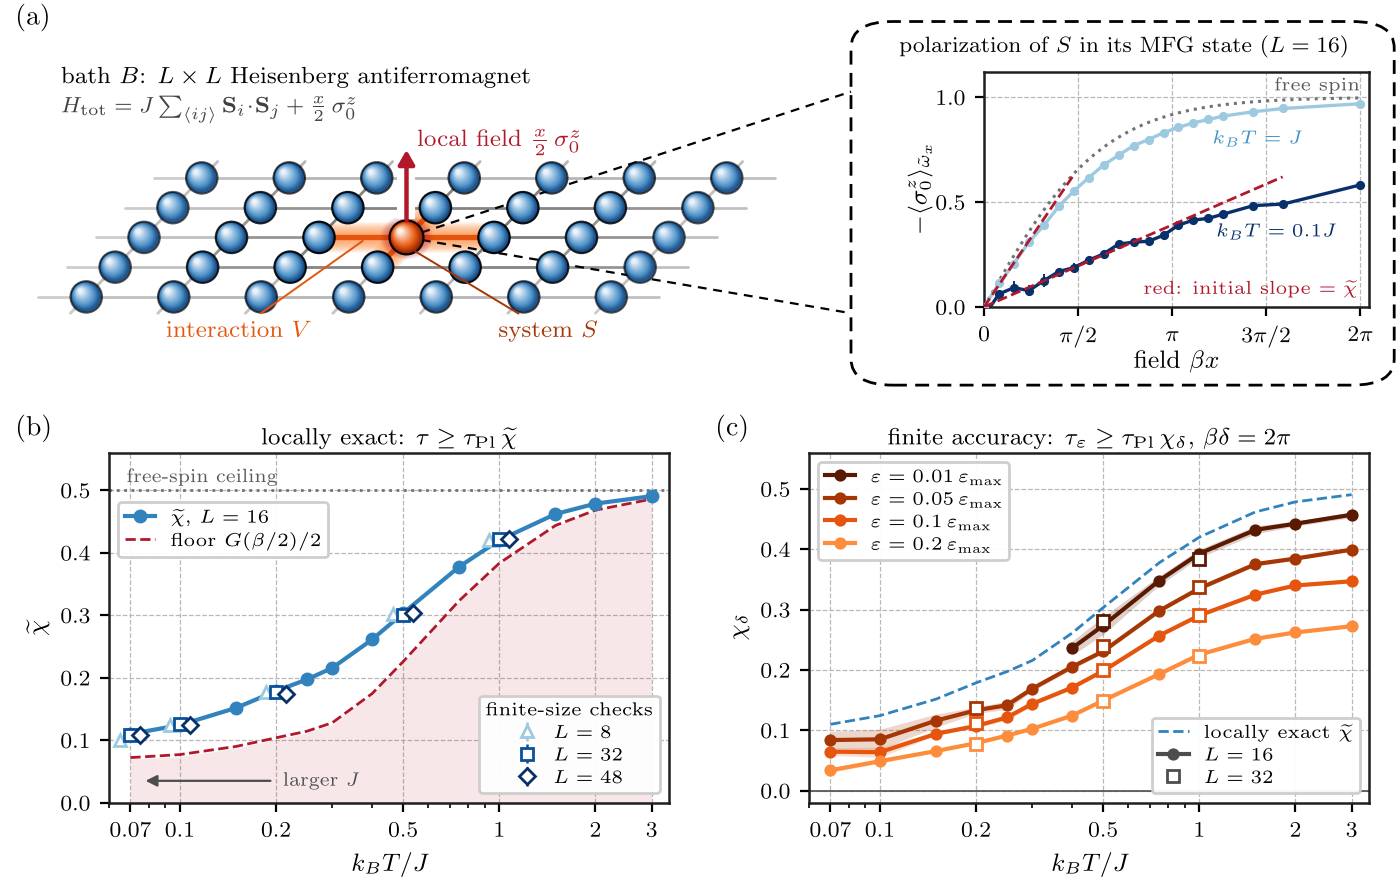

In [6]:
OFFS = {8: 0.93, 32: 1.0, 48: 1.075}     # small horizontal offsets of the spot-check symbols
T_RESP = (1.0, 0.1)                      # temperatures shown in the response inset
REL_MAX = 0.2                            # drop points with bootstrap error >= 20% of the value


def series(L, key):
    """(T, value, error) against temperature, for one lattice size."""
    rows = sort_by(select(C, L=L), 'T')
    return column(rows, 'T', key, key + '_err')


def mfg_curve(L, T):
    rows = sort_by(select(M, L=L, T=T), 'betax')
    u, m, me = column(rows, 'betax', 'mz', 'mz_err')
    return (np.concatenate([-u[::-1][:-1], u]),
            np.concatenate([-m[::-1][:-1], m]),
            np.concatenate([me[::-1][:-1], me]))


def fin(L, eps_f):
    """(T, chi_delta, error) for one size and accuracy, with the noisy points dropped."""
    rows = sort_by([r for r in F if r['L'] == L and abs(r['eps_over_epsmax'] - eps_f) < 1e-12], 'T')
    T, v, e = column(rows, 'T', 'chi_lcl', 'err_lcl')
    ok = e < REL_MAX * np.abs(v)
    return T[ok], v[ok], e[ok]


fig = plt.figure(figsize=(ps.DBL_W, 4.4))

# ---------------- (a) schematic ----------------
axs = fig.add_axes([0.0, 0.5651, 0.575, 0.4251])
d = sc.draw_lattice(axs, R=0.18, field_len=1.0)
axs.set_aspect('equal'); axs.axis('off')
axs.set_xlim(-4.6, 4.6); axs.set_ylim(-1.25, 2.05)
o, tip = d['o'], d['tip']
axs.text(tip[0] + 0.12, tip[1] - 0.06, r'local field $\tfrac{x}{2}\,\sigma^z_0$',
         color=RED, fontsize=8.5, va='bottom')
lab = dict(fontsize=8.5, va='top', zorder=30)
pV = 0.5 * (sc.proj(-1, 0) + o)
axs.annotate(r'system $S$', xy=o + np.array([0.1, -0.16]), xytext=(1.05, -0.95), color='#a63603',
             ha='left', arrowprops=dict(arrowstyle='-', color='#a63603', lw=0.7, shrinkA=1, shrinkB=0), **lab)
axs.annotate(r'interaction $V$', xy=pV + np.array([0, -0.04]), xytext=(-2.75, -0.95), color='#e6550d',
             ha='left', arrowprops=dict(arrowstyle='-', color='#e6550d', lw=0.7, shrinkA=1, shrinkB=0), **lab)
axs.text(-3.95, 1.95, r'bath $B$: $L\times L$ Heisenberg antiferromagnet', fontsize=8.5, va='top')
axs.text(-3.95, 1.62, r'$H_{\rm tot}=J\sum_{\langle ij\rangle}\mathbf S_i\!\cdot\!\mathbf S_j'
                      r'+\tfrac{x}{2}\,\sigma^z_0$', fontsize=8, va='top', color='0.25')

# ---------------- (a) measured response; its initial slope is the bound ----------------
axr = fig.add_axes([0.70, 0.6589, 0.275, 0.2669])
uu = np.linspace(0, 2 * np.pi, 300)
axr.plot(uu, np.tanh(uu / 2), color='0.45', ls=':', lw=1.1, zorder=2)
for T, c in zip(T_RESP, (L_COLOR[8], L_COLOR[48])):
    u, m, me = mfg_curve(16, T)
    k = u >= 0
    axr.errorbar(u[k], -m[k], me[k], fmt='-o', color=c, lw=1.2, ms=2.3, elinewidth=0.7, zorder=3)
    ch = select(C, L=16, T=T)[0]['chi']
    ut = np.array([0, 0.62 / max(ch, 0.5 * 0.62 / 2.6)])
    axr.plot(ut, ch * ut, color=RED, ls='--', lw=1.0, zorder=4)
axr.set_xlim(0, 2 * np.pi + 0.15); axr.set_ylim(0, 1.12)
axr.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
axr.set_xticklabels(['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
axr.set_yticks([0, 0.5, 1])
axr.set_xlabel(r'field $\beta x$', labelpad=1)
axr.set_ylabel(r'$-\langle\sigma^z_0\rangle_{\tilde\omega_x}$', labelpad=1)
grid(axr)
axr.text(2 * np.pi, 1.015, 'free spin', fontsize=6.8, color='0.35', ha='right', va='bottom')
for T, c, xl in zip(T_RESP, (BLUES_DARK, L_COLOR[48]), (1.45 * np.pi, 1.55 * np.pi)):
    u, m, _ = mfg_curve(16, T)
    axr.text(xl, np.interp(xl, u, -m) - 0.09, (r'$k_BT=J$' if T == 1 else fr'$k_BT={T:g}J$'),
             fontsize=6.8, color=c, ha='center', va='top')
axr.text(0.97, 0.04, r'red: initial slope $=\widetilde\chi$', transform=axr.transAxes,
         fontsize=6.8, color=RED, ha='right', va='bottom')
fr = FancyBboxPatch((0.605, 0.57), 0.388, 0.4132, boxstyle='round,pad=0,rounding_size=0.03',
                    transform=fig.transFigure, fc='none', ec='k', lw=1.0, ls=(0, (5, 3)), zorder=0)
fig.add_artist(fr)
fig.text(0.80, 0.9486, r'polarization of $S$ in its MFG state ($L=16$)', ha='center', fontsize=8)
inv = axs.transData.inverted()
for yy in (0.6145, 0.9407):
    end = inv.transform(fig.transFigure.transform((0.605, yy)))
    axs.plot([o[0], end[0]], [o[1], end[1]], color='k', lw=0.8, ls=(0, (4, 3)), zorder=5, clip_on=False)

# ---------------- (b) locally exact bound ----------------
axb = fig.add_axes([0.075, 0.0955, 0.4, 0.3977])
axb.axhline(0.5, color='0.45', ls=':', lw=1.0, zorder=1)
axb.text(0.068, 0.507, 'free-spin ceiling', fontsize=7, color='0.35', ha='left', va='bottom')
T16, v16, e16 = series(16, 'chi')
axb.fill_between(T16, v16 - e16, v16 + e16, color=L_COLOR[16], alpha=0.22, lw=0, zorder=2)
axb.plot(T16, v16, '-o', color=L_COLOR[16], zorder=4, label=r'$\widetilde\chi$, $L=16$')
for L in (8, 32, 48):
    T, v, e = series(L, 'chi')
    if not len(T):
        continue
    axb.errorbar(T * OFFS[L], v, e, fmt=L_MARK[L], color=L_COLOR[L], mfc='white', mew=1.0,
                 ms=4.2, elinewidth=0.9, zorder=5, label=fr'$L={L}$')
Tg, g16, ge16 = series(16, 'GhalfVar')
axb.fill_between(Tg, 0, g16 / 2 - ge16 / 2, color=RED, alpha=0.10, lw=0, zorder=1)
axb.plot(Tg, g16 / 2, color=RED, ls='--', lw=1.0, zorder=3, label=r'floor $G(\beta/2)/2$')
axb.set_xscale('log'); axb.set_xlim(0.06, 3.4); axb.set_ylim(0, 0.56)
axb.set_xticks([0.07, 0.1, 0.2, 0.5, 1, 2, 3])
axb.set_xticklabels(['0.07', '0.1', '0.2', '0.5', '1', '2', '3'])
axb.set_xlabel(r'$k_BT/J$'); axb.set_ylabel(r'$\widetilde\chi$')
axb.set_title(r'locally exact: $\tau\geq\tau_{\rm Pl}\,\widetilde\chi$', fontsize=8.5, pad=3)
axb.annotate('', xy=(0.075, 0.035), xytext=(0.2, 0.035),
             arrowprops=dict(arrowstyle='-|>', color='0.3', lw=0.8))
axb.text(0.21, 0.035, r'larger $J$', fontsize=7, color='0.3', va='center')
grid(axb)
hb, lb = axb.get_legend_handles_labels()
main = [i for i, s in enumerate(lb) if 'L=16' in s or 'floor' in s]
sizes = [i for i in range(len(lb)) if i not in main]
la = axb.legend([hb[i] for i in main], [lb[i] for i in main], loc='upper left',
                bbox_to_anchor=(0.0, 0.885), fontsize=6.8, borderpad=0.35, handlelength=1.6)
axb.add_artist(la)
axb.legend([hb[i] for i in sizes], [lb[i] for i in sizes], loc='lower right', fontsize=6.8,
           borderpad=0.35, handlelength=1.2, title='finite-size checks', title_fontsize=6.8)

# ---------------- (c) finite accuracy ----------------
axc = fig.add_axes([0.575, 0.0955, 0.4, 0.3977])
axc.plot(T16, v16, color=L_COLOR[16], ls='--', lw=1.0, zorder=2)
for ef, c in EPS_COLOR_QMC.items():
    T, v, e = fin(16, ef)
    if len(T):
        axc.fill_between(T, v - e, v + e, color=c, alpha=0.2, lw=0, zorder=2)
        axc.plot(T, v, '-o', color=c, ms=3.4, zorder=4)
    T, v, e = fin(32, ef)
    if len(T):
        axc.errorbar(T, v, e, fmt='s', color=c, mfc='white', mew=1.0, ms=4.4, elinewidth=0.9, zorder=5)
axc.axhline(0, color='0.3', lw=0.6)
axc.set_xscale('log'); axc.set_xlim(0.06, 3.4); axc.set_ylim(-0.02, 0.56)
axc.set_xticks([0.07, 0.1, 0.2, 0.5, 1, 2, 3])
axc.set_xticklabels(['0.07', '0.1', '0.2', '0.5', '1', '2', '3'])
axc.set_xlabel(r'$k_BT/J$'); axc.set_ylabel(r'$\chi_\delta$')
axc.set_title(r'finite accuracy: $\tau_\varepsilon\geq\tau_{\rm Pl}\,\chi_\delta$, $\beta\delta=2\pi$',
              fontsize=8.5, pad=3)
h1 = [Line2D([], [], color=c, marker='o', ms=3.4, label=fr'$\varepsilon={e:g}\,\varepsilon_{{\max}}$')
      for e, c in EPS_COLOR_QMC.items()]
axc.add_artist(axc.legend(handles=h1, loc='upper left', fontsize=6.8, borderpad=0.35, handlelength=1.6))
h2 = [Line2D([], [], color=L_COLOR[16], ls='--', lw=1.0, label=r'locally exact $\widetilde\chi$'),
      Line2D([], [], color='0.3', marker='o', ls='-', ms=3.4, label=r'$L=16$'),
      Line2D([], [], color='0.3', marker='s', ls='none', mfc='white', ms=4.4, label=r'$L=32$')]
axc.legend(handles=h2, loc='lower right', fontsize=6.8, borderpad=0.35, handlelength=1.6)
grid(axc)

yb = axb.get_position().y1 + 0.012
for s, xy in (('(a)', (0.008, 0.972)), ('(b)', (0.008, yb)), ('(c)', (0.508, yb))):
    fig.text(*xy, s, fontsize=10, ha='left', va='bottom')
# This figure places its axes by hand on a full-page canvas, so unlike the other figures it is
# saved with a tight bounding box.
fig.savefig(FIGS / 'heisenberg_bound.pdf', bbox_inches='tight');

## 5. Reading the figure

**Finite size.** The $L=16$, 32 and 48 curves in panel (b) agree within 3%, so the bound has
converged in the lattice size; only the smallest lattice, $L=8$, falls below them at the lowest
temperature, where the finite-size gap starts to matter. That is physics, not a convergence
failure, and it is why the strong-coupling statement requires $L\to\infty$ *before* $T\to0$.

**The physical mechanism.** The bound decreases with the coupling but, unlike in the
resonant-level model where $\widetilde\chi\to4/(\pi\beta g^2)$, it does not vanish: the floor
stays finite down to the lowest temperature simulated, $k_BT=0.07J$, i.e. up to
$J\simeq14\,k_BT$, and $\tau\gtrsim0.1\,\hbar/k_BT$. The gap between $\widetilde\chi$ and the
floor — the fast fluctuations — closes roughly linearly in $k_BT/J$, as expected for
fluctuations at frequencies of order $J/\hbar$.

Unlike the dark mode of the double quantum dot and $\sigma_z$ in the spin–boson model,
$\sigma^z_0$ here does **not** commute with the interaction. Its slow fluctuations are instead a
collective property of the bath: the antiferromagnetic correlations extend over large regions
at low temperature, and the system spin follows a locally ordered background whose orientation
changes slowly.

**Against the criterion of Sec. III B.** $\sqrt{\mathrm{Var}(\hat\kappa)}=1/2$ exactly here by
SU(2), so the fluctuations are as large as they can be; what decides the bound is whether they
stay correlated over $\hbar\beta$, and the floor says a finite fraction of them does. This is
the protected case of the criterion — and the opposite of the resonant-level model, where the
occupation decorrelates on $\hbar/g^2\ll\hbar\beta$ and the bound loses its Planckian character.

## 6. Recomputing the data

The pipeline is in `src/heisenberg/` and writes into `data/heisenberg/`. It needs a C++
compiler, and the production runs are the expensive part of the whole paper.

```
g++ -O3 -march=native -o src/heisenberg/sse/sse_t src/heisenberg/sse/sse_t.cpp
python src/heisenberg/sse/run_production.py [ncores]      # writes data/heisenberg/raw/
python src/heisenberg/sse/run_rebin.py                    # bin-independence check
python src/heisenberg/sse/run_drift.py                    # equilibration check
python src/heisenberg/analysis/analyse.py                 # the CSV files read above
```

| script | role |
|---|---|
| `sse/sse_t.cpp` | SSE with directed loops, per-bond couplings and $\mathcal C(\tau)$ sampling |
| `sse/lib.py`, `sse/libt.py` | lattice and model tables, input files, exact diagonalization, jackknife |
| `sse/runlib.py` | run driver; seeds are `crc32` of the run tag, so runs are reproducible |
| `sse/run_production.py` | the five production sets: the $L=16$ temperature scan, the finite-size spot checks, extra seeds at $L=32$, and the two field scans |
| `sse/validate_ed.py`, `sse/validate_seeds.py` | validation against exact diagonalization on $4\times2$ clusters, and seed reproducibility |
| `analysis/analyse.py` | estimators, combination over runs, split-sample and LCL $\chi_\delta$, bootstrap errors |

Cost scales roughly as $\beta L^2$: one $L=48$, $k_BT=0.1J$ run is about 31 500 operators and
took 312 s per core. The raw per-bin output (1089 runs) is not distributed; the four CSV files
in `data/heisenberg/` are the complete input to this notebook and to Fig. 5.